In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras as keras

import kagglehub
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

Using Colab cache for faster access to the 'creditcardfraud' dataset.


In [2]:
df = pd.read_csv(path+"/creditcard.csv")
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [3]:
keras.backend.clear_session()

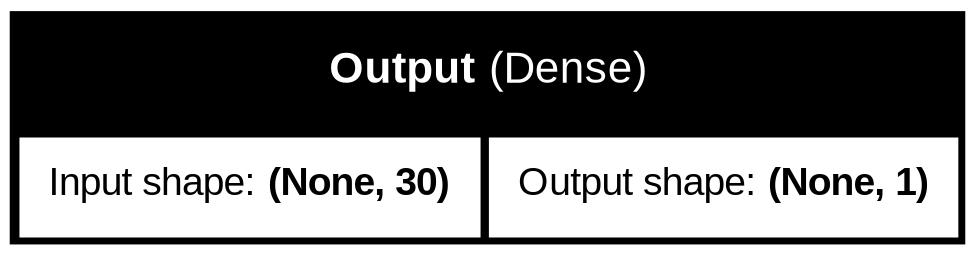

In [4]:
model = keras.models.Sequential(
    [
        keras.layers.Input((df.shape[1] - 1,)),
        keras.layers.Dense(1, 'sigmoid', name='Output')
    ],
    name="Detection_Model"
)
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

keras.utils.plot_model(model, show_shapes=True, show_layer_names=True)

In [5]:
model.summary()

Model: "Detection_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Output (Dense)                  │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    df.drop(columns=['Class']),
    df['Class'],
    batch_size=128,
    validation_split=0.5,
    epochs=5,
    verbose=1
)

Epoch 1/5
1113/1113 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9948 - loss: 0.3732 - val_accuracy: 0.9985 - val_loss: 0.0602
Epoch 2/5
1113/1113 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9980 - loss: 0.0522 - val_accuracy: 0.9984 - val_loss: 0.1507
Epoch 3/5
1113/1113 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9983 - loss: 0.0904 - val_accuracy: 0.9987 - val_loss: 0.0767
Epoch 4/5
1113/1113 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9973 - loss: 0.6395 - val_accuracy: 0.9984 - val_loss: 1.3256
Epoch 5/5
1113/1113 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9981 - loss: 0.1886 - val_accuracy: 0.9987 - val_loss: 0.0791


In [7]:
model.save("credit_card_model.keras")
print("\nModel successfully saved to 'credit_card_model.keras'")


Model successfully saved to 'credit_card_model.keras'


In [8]:
loaded_model = keras.models.load_model("credit_card_model.keras")
print("Model successfully loaded!")

sample_data = df.drop(columns=['Class']).head(5)
sample_target = df['Class'].head(5)
predictions = loaded_model.predict(sample_data)

print("\nPredictions for the first 5 samples:")
for i, pred in enumerate(predictions):
    print(f"Sample {i+1} Fraud Probability: {pred[0]:.6f} | Actual Probability: {sample_target[i]}")

Model successfully loaded!
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step

Predictions for the first 5 samples:
Sample 1 Fraud Probability: 0.139783 | Actual Probability: 0
Sample 2 Fraud Probability: 0.149071 | Actual Probability: 0
Sample 3 Fraud Probability: 0.097374 | Actual Probability: 0
Sample 4 Fraud Probability: 0.111107 | Actual Probability: 0
Sample 5 Fraud Probability: 0.138598 | Actual Probability: 0
